# Prediksi Stres pada Pengguna Media Sosial Menggunakan Logistic Regression dan Random Forest Classifier berbasis Fitur Linguistik dan Sosial

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
stres = pd.read_csv('/content/drive/Shareddrives/project KA/stress.csv')
stres.head()

,subreddit,post_id,sentence_range,text,id,label,confidence,social_timestamp,social_karma,syntax_ari,...,lex_dal_min_pleasantness,lex_dal_min_activation,lex_dal_min_imagery,lex_dal_avg_activation,lex_dal_avg_imagery,lex_dal_avg_pleasantness,social_upvote_ratio,social_num_comments,syntax_fk_grade,sentiment
0,ptsd,8601tu,"(15, 20)","He said he had not felt that way before, sugge...",33181,1,0.8,1521614353,5,1.806818,...,1.000,1.1250,1.0,1.77000,1.52211,1.89556,0.86,1,3.253573,-0.002742
1,assistance,8lbrx9,"(0, 5)","Hey there r/assistance, Not sure if this is th...",2606,0,1.0,1527009817,4,9.429737,...,1.125,1.0000,1.0,1.69586,1.62045,1.88919,0.65,2,8.828316,0.292857
2,ptsd,9ch1zh,"(15, 20)",My mom then hit me with the newspaper and it s...,38816,1,0.8,1535935605,2,7.769821,...,1.000,1.1429,1.0,1.83088,1.58108,1.85828,0.67,0,7.841667,0.011894
3,relationships,7rorpp,"[5, 10]","until i met my new boyfriend, he is amazing, h...",239,1,0.6,1516429555,0,2.667798,...,1.000,1.1250,1.0,1.75356,1.52114,1.98848,0.50,5,4.104027,0.141671
4,survivorsofabuse,9p2gbc,"[0, 5]",October is Domestic Violence Awareness Month a...,1421,1,0.8,1539809005,24,7.554238,...,1.000,1.1250,1.0,1.77644,1.64872,1.81456,1.00,1,7.910952,-0.204167


In [ ]:
stres.shape


(2838, 116)

# CLEANING

In [ ]:
stres.shape
stres.columns

Index(['subreddit', 'post_id', 'sentence_range', 'text', 'id', 'label',
       'confidence', 'social_timestamp', 'social_karma', 'syntax_ari',
       ...
       'lex_dal_min_pleasantness', 'lex_dal_min_activation',
       'lex_dal_min_imagery', 'lex_dal_avg_activation', 'lex_dal_avg_imagery',
       'lex_dal_avg_pleasantness', 'social_upvote_ratio',
       'social_num_comments', 'syntax_fk_grade', 'sentiment'],
      dtype='object', length=116)

In [ ]:
stres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2838 entries, 0 to 2837
Columns: 116 entries, subreddit to sentiment
dtypes: float64(106), int64(6), object(4)
memory usage: 2.5+ MB


In [ ]:
stres.select_dtypes(include='object').columns


Index(['subreddit', 'post_id', 'sentence_range', 'text'], dtype='object')

In [ ]:
stres.isnull().sum()

,0
subreddit,0
post_id,0
sentence_range,0
text,0
id,0
...,...
lex_dal_avg_pleasantness,0
social_upvote_ratio,0
social_num_comments,0
syntax_fk_grade,0


In [ ]:
stres.duplicated().sum()

np.int64(0)

In [ ]:
stres = stres.drop(columns=['subreddit', 'post_id', 'sentence_range', 'text', 'id', 'social_timestamp'])

##Rename columns

In [ ]:
rename_map = {
    "label" : "label",
    "confidence" : "confidence",
    "social_karma": "karma",
    "social_upvote_ratio": "upratio",
    "social_num_comments": "comments",
    "syntax_ari": "ari",
    "syntax_fk_grade": "fkgrade",
    "sentiment": "sentiment",

    "lex_dal_max_pleasantness": "pleasantmax",
    "lex_dal_max_activation": "activemax",
    "lex_dal_max_imagery": "imagerymax",
    "lex_dal_min_pleasantness": "pleasantmin",
    "lex_dal_min_activation": "activemin",
    "lex_dal_min_imagery": "imagerymin",
    "lex_dal_avg_activation": "activeavg",
    "lex_dal_avg_imagery": "imageryavg",
    "lex_dal_avg_pleasantness": "pleasantavg",

    "lex_liwc_WC": "wordcount",
    "lex_liwc_Analytic": "analytic",
    "lex_liwc_Clout": "clout",
    "lex_liwc_Authentic": "authentic",
    "lex_liwc_Tone": "tone",
    "lex_liwc_WPS": "wordsent",
    "lex_liwc_Sixltr": "sixltr",
    "lex_liwc_Dic": "dictionary",

    "lex_liwc_function": "function",
    "lex_liwc_pronoun": "pronoun",
    "lex_liwc_ppron": "ppron",
    "lex_liwc_i": "iword",
    "lex_liwc_we": "we",
    "lex_liwc_you": "you",
    "lex_liwc_shehe": "shehe",
    "lex_liwc_they": "they",
    "lex_liwc_ipron": "ipron",
    "lex_liwc_article": "article",
    "lex_liwc_prep": "prep",
    "lex_liwc_auxverb": "auxverb",
    "lex_liwc_adverb": "adverb",
    "lex_liwc_conj": "conjunction",
    "lex_liwc_negate": "negate",
    "lex_liwc_verb": "verb",
    "lex_liwc_adj": "adjective",
    "lex_liwc_compare": "compare",
    "lex_liwc_interrog": "interrog",
    "lex_liwc_number": "number",
    "lex_liwc_quant": "quantifier",

    "lex_liwc_affect": "affect",
    "lex_liwc_posemo": "posemo",
    "lex_liwc_negemo": "negemo",
    "lex_liwc_anx": "anxiety",
    "lex_liwc_anger": "anger",
    "lex_liwc_sad": "sadness",

    "lex_liwc_social": "social",
    "lex_liwc_family": "family",
    "lex_liwc_friend": "friend",
    "lex_liwc_female": "female",
    "lex_liwc_male": "male",
    "lex_liwc_cogproc": "cognitive",
    "lex_liwc_insight": "insight",
    "lex_liwc_cause": "cause",
    "lex_liwc_discrep": "discrep",
    "lex_liwc_tentat": "tentative",
    "lex_liwc_certain": "certain",
    "lex_liwc_differ": "differ",


    "lex_liwc_percept": "percept",
    "lex_liwc_see": "see",
    "lex_liwc_hear": "hear",
    "lex_liwc_feel": "feel",


    "lex_liwc_bio": "bio",
    "lex_liwc_body": "body",
    "lex_liwc_health": "health",
    "lex_liwc_sexual": "sexual",
    "lex_liwc_ingest": "ingest",

    "lex_liwc_drives": "drives",
    "lex_liwc_affiliation": "affiliation",
    "lex_liwc_achieve": "achieve",
    "lex_liwc_power": "power",
    "lex_liwc_reward": "reward",
    "lex_liwc_risk": "risk",


    "lex_liwc_focuspast": "past",
    "lex_liwc_focuspresent": "present",
    "lex_liwc_focusfuture": "future",
    "lex_liwc_time": "time",
    "lex_liwc_relativ": "relativ",
    "lex_liwc_space": "space",

    "lex_liwc_work": "work",
    "lex_liwc_leisure": "leisure",
    "lex_liwc_home": "home",
    "lex_liwc_money": "money",
    "lex_liwc_relig": "relig",
    "lex_liwc_death": "death",

    "lex_liwc_informal": "informal",
    "lex_liwc_swear": "swear",
    "lex_liwc_netspeak": "netspeak",
    "lex_liwc_assent": "assent",
    "lex_liwc_nonflu": "nonflu",
    "lex_liwc_filler": "filler",

    "lex_liwc_AllPunc": "punc",
    "lex_liwc_Period": "period",
    "lex_liwc_Comma": "comma",
    "lex_liwc_Colon": "colon",
    "lex_liwc_SemiC": "semicolon",
    "lex_liwc_QMark": "qmark",
    "lex_liwc_Exclam": "exclam",
    "lex_liwc_Dash": "dash",
    "lex_liwc_Quote": "quote",
    "lex_liwc_Apostro": "apostro",
    "lex_liwc_Parenth": "parenthesis",
    "lex_liwc_OtherP": "otherp"
}

In [ ]:
df = stres.rename(columns=rename_map)

In [ ]:
print("Total kolom:", len(df.columns))
df.columns


Total kolom: 110


Index(['label', 'confidence', 'karma', 'ari', 'wordcount', 'analytic', 'clout',
       'authentic', 'tone', 'wordsent',
       ...
       'pleasantmin', 'activemin', 'imagerymin', 'activeavg', 'imageryavg',
       'pleasantavg', 'upratio', 'comments', 'fkgrade', 'sentiment'],
      dtype='object', length=110)

#EDA

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2838 entries, 0 to 2837
Columns: 110 entries, label to sentiment
dtypes: float64(106), int64(4)
memory usage: 2.4 MB


In [ ]:
df.isna().sum()

,0
label,0
confidence,0
karma,0
ari,0
wordcount,0
...,...
pleasantavg,0
upratio,0
comments,0
fkgrade,0


In [ ]:
len(df)

2838

##statistik deskripsi

In [ ]:
df.describe()

,label,confidence,karma,ari,wordcount,analytic,clout,authentic,tone,wordsent,...,pleasantmin,activemin,imagerymin,activeavg,imageryavg,pleasantavg,upratio,comments,fkgrade,sentiment
count,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,...,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000,2838.000000
mean,0.524313,0.808972,18.262156,4.684272,85.996124,35.240941,40.948231,67.044249,33.428157,18.189475,...,1.088001,1.120099,1.000211,1.722759,1.536400,1.879385,0.843517,9.948555,5.448836,0.040740
std,0.499497,0.177038,79.419166,3.316435,32.334887,26.486189,31.587117,32.880644,35.334770,9.516060,...,0.117159,0.085227,0.006500,0.047835,0.102971,0.058932,0.174794,21.798032,2.535829,0.195490
min,0.000000,0.428571,0.000000,-6.620000,5.000000,1.000000,1.000000,1.000000,1.000000,2.400000,...,1.000000,1.000000,1.000000,1.485400,1.200000,1.561150,0.140000,0.000000,-1.918000,-1.000000
25%,0.000000,0.600000,2.000000,2.464243,65.000000,12.410000,12.135000,41.070000,1.420000,13.400000,...,1.000000,1.000000,1.000000,1.691430,1.469745,1.841782,0.750000,2.000000,3.729973,-0.072222
50%,1.000000,0.800000,5.000000,4.321886,81.000000,29.420000,33.520000,80.710000,25.770000,16.775000,...,1.000000,1.142900,1.000000,1.721430,1.530295,1.878250,0.890000,5.000000,5.210000,0.044821
75%,1.000000,1.000000,10.000000,6.505657,101.000000,55.057500,69.320000,96.180000,61.550000,21.000000,...,1.142900,1.142900,1.000000,1.751760,1.596030,1.916243,1.000000,10.000000,6.855217,0.166667
max,1.000000,1.000000,1435.000000,24.074231,310.000000,99.000000,99.000000,99.000000,99.000000,233.000000,...,1.900000,1.500000,1.200000,2.007400,2.066670,2.158490,1.000000,416.000000,21.198919,1.000000


##Deteksi outlier (IQR)

In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

outlier_count = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_count[col] = count

outlier_count = pd.Series(outlier_count).sort_values(ascending=False)

outlier_count.head()


,0
qmark,632
dash,574
ingest,520
imagerymax,496
netspeak,447


In [ ]:
top10_cols = outlier_count.head(10)
print(top10_cols)

qmark         632
dash          574
ingest        520
imagerymax    496
netspeak      447
quote         445
otherp        415
swear         408
you           396
female        389
dtype: int64


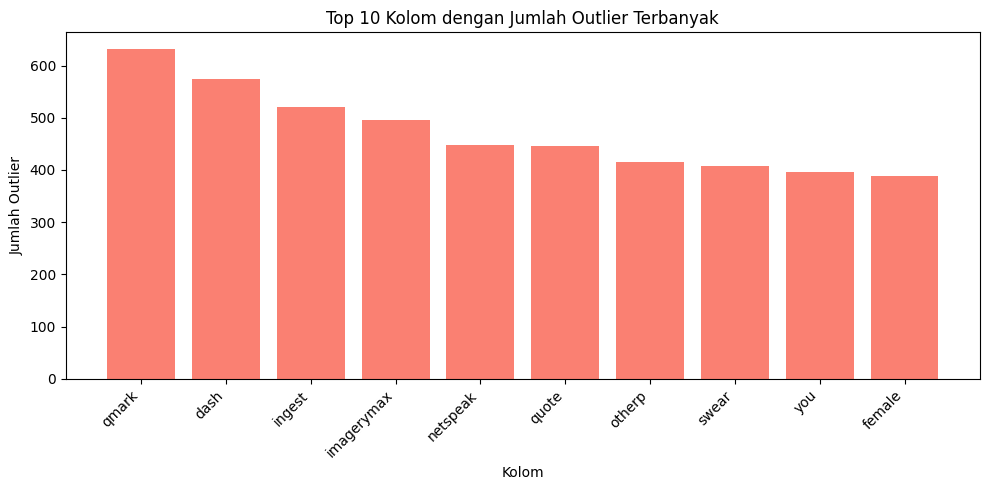

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(top10_cols.index, top10_cols.values, color='salmon')
plt.xticks(rotation=45, ha='right')
plt.title("Top 10 Kolom dengan Jumlah Outlier Terbanyak")
plt.xlabel("Kolom")
plt.ylabel("Jumlah Outlier")
plt.tight_layout()
plt.show()



##Distribusi label

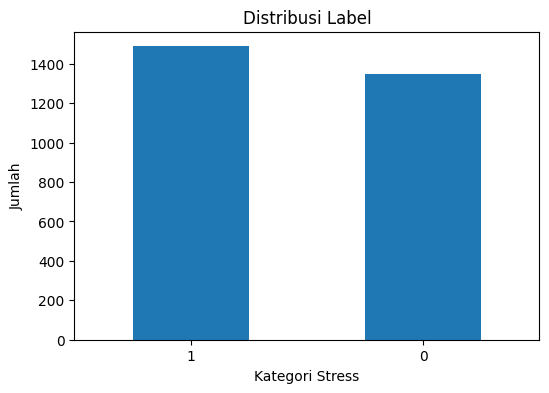

In [ ]:
df['label'].value_counts().plot(kind='bar', figsize=(6,4))
plt.title('Distribusi Label')
plt.xlabel('Kategori Stress')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.show()


##Korelasi Setiap Fitur terhadap Target

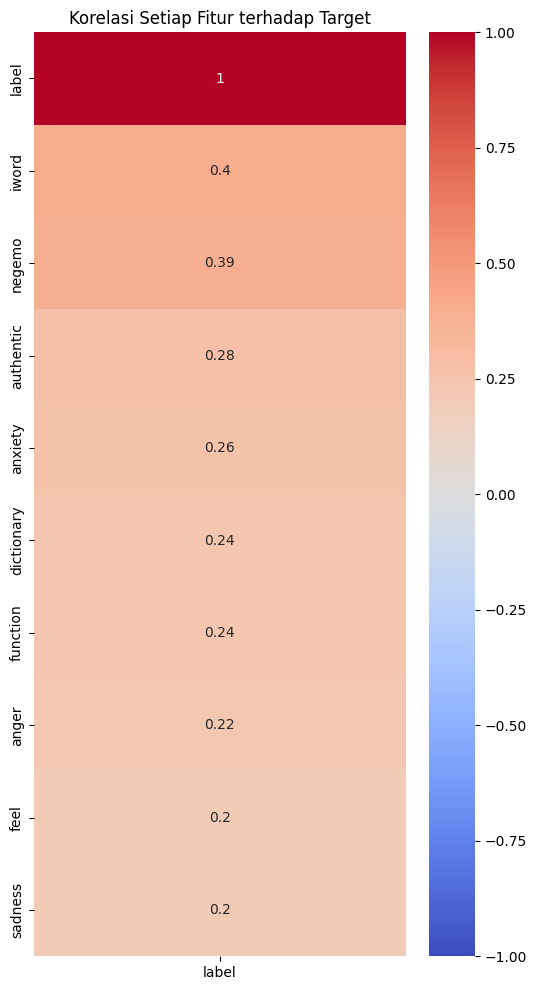

In [ ]:
corr= df.corr()['label'].sort_values(ascending=False).head(10)
plt.figure(figsize=(6, 12))
sns.heatmap(corr.to_frame(), annot=True, cmap="coolwarm", vmin=-1,vmax=1)
plt.title("Korelasi Setiap Fitur terhadap Target")
plt.show()


In [ ]:
display(corr)

,label
label,1.000000
iword,0.400440
negemo,0.387979
authentic,0.275282
anxiety,0.260146
dictionary,0.241536
function,0.236932
anger,0.218990
feel,0.198048
sadness,0.196268


#Feature Selection

##Feature Importance

Menentukan fitur & Label

In [ ]:
X = df.drop('label', axis=1)
y = df['label']

In [ ]:
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train_full, y_train)

importances = pd.Series(rf.feature_importances_, index=X_train_full.columns)
importances = importances.sort_values(ascending=False)
print(importances.head(50))


tone           0.049563
negemo         0.049114
clout          0.042979
iword          0.042087
sentiment      0.026325
authentic      0.022587
social         0.021217
anxiety        0.019358
present        0.017917
pleasantmin    0.016970
posemo         0.016925
function       0.014883
dictionary     0.014785
analytic       0.014050
apostro        0.013248
affect         0.013231
ppron          0.012657
activeavg      0.011933
feel           0.011472
past           0.011363
negate         0.010939
pronoun        0.010848
anger          0.010843
confidence     0.010828
adverb         0.010410
comma          0.010128
conjunction    0.010005
punc           0.009906
space          0.009905
pleasantavg    0.009651
imageryavg     0.009555
relativ        0.009383
article        0.009376
sixltr         0.009229
time           0.009009
wordsent       0.008939
wordcount      0.008891
auxverb        0.008881
differ         0.008801
ipron          0.008726
verb           0.008670
adjective      0

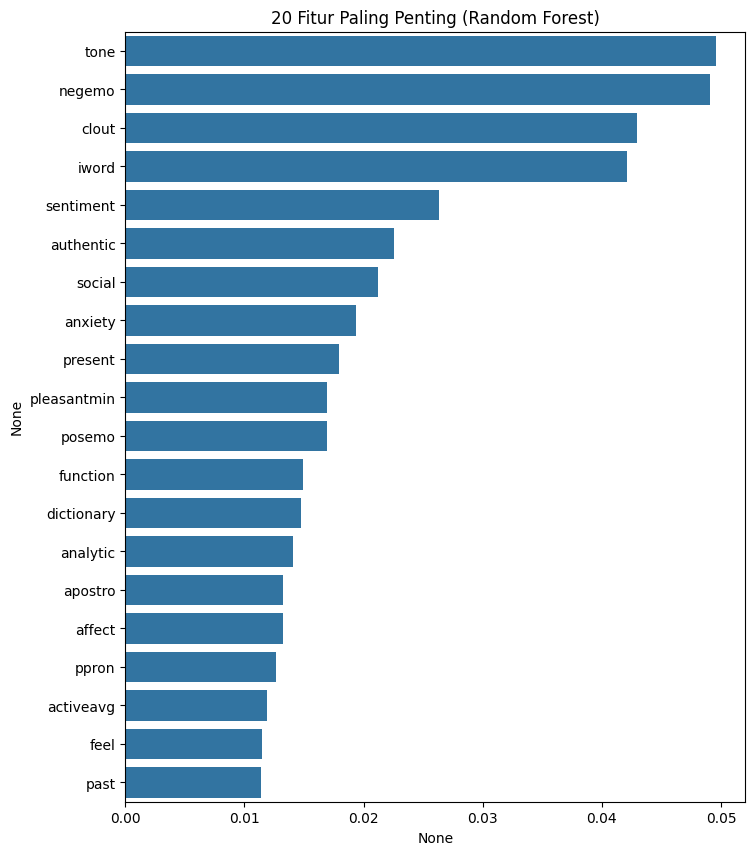

In [ ]:
plt.figure(figsize=(8, 10))
sns.barplot(x=importances.head(20), y=importances.head(20).index)
plt.title("20 Fitur Paling Penting (Random Forest)")
plt.show()

#Modeling



Memilih 50 fitur terbaik

In [ ]:
top_50_features = importances.head(50).index.tolist()


In [ ]:
X_train = X_train_full[top_50_features]
X_test = X_test_full[top_50_features]



Robust Scaler

In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression

In [ ]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Logistic Regression Classifier

In [ ]:
lr = LogisticRegression(max_iter=1000,random_state=42,class_weight="balanced")
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

In [ ]:
lr2 = LogisticRegression(max_iter=1000, random_state=42, class_weight = 'balanced')
lr2.fit(X_train, y_train)
y_pred_lr2 = lr2.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Random Forest Classifier

In [ ]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight= 'balanced')
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

#Evaluasi model

In [ ]:
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluasi {model_name}")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, average='weighted'))
    print("Recall   :", recall_score(y_true, y_pred, average='weighted'))
    print("F1-score :", f1_score(y_true, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))

evaluate_model(y_test, y_pred_lr, "Logistic Regression(Robust Scaled)")

Evaluasi Logistic Regression(Robust Scaled)
Accuracy : 0.7711267605633803
Precision: 0.7744379632324951
Recall   : 0.7711267605633803
F1-score : 0.7711636504290139
Confusion Matrix:
 [[218  52]
 [ 78 220]]
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.81      0.77       270
           1       0.81      0.74      0.77       298

    accuracy                           0.77       568
   macro avg       0.77      0.77      0.77       568
weighted avg       0.77      0.77      0.77       568



In [ ]:
evaluate_model(y_test, y_pred_lr2, "Logistic Regression(unscaled)")

Evaluasi Logistic Regression(unscaled)
Accuracy : 0.7711267605633803
Precision: 0.7732668648956502
Recall   : 0.7711267605633803
F1-score : 0.771240288955958
Confusion Matrix:
 [[215  55]
 [ 75 223]]
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.80      0.77       270
           1       0.80      0.75      0.77       298

    accuracy                           0.77       568
   macro avg       0.77      0.77      0.77       568
weighted avg       0.77      0.77      0.77       568



In [ ]:
evaluate_model(y_test, y_pred_rf, "Random Forest")

Evaluasi Random Forest
Accuracy : 0.778169014084507
Precision: 0.7781055987667297
Recall   : 0.778169014084507
F1-score : 0.7781276436578217
Confusion Matrix:
 [[206  64]
 [ 62 236]]
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.76      0.77       270
           1       0.79      0.79      0.79       298

    accuracy                           0.78       568
   macro avg       0.78      0.78      0.78       568
weighted avg       0.78      0.78      0.78       568



Confusion Matrix

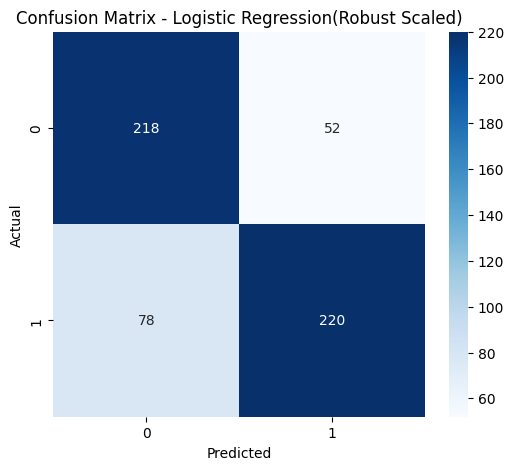

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, model_name):
    labels = sorted(y_test.unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    # cm = confusion_matrix(y_true, y_pred, labels=y_test.unique())
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()


plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression(Robust Scaled)")

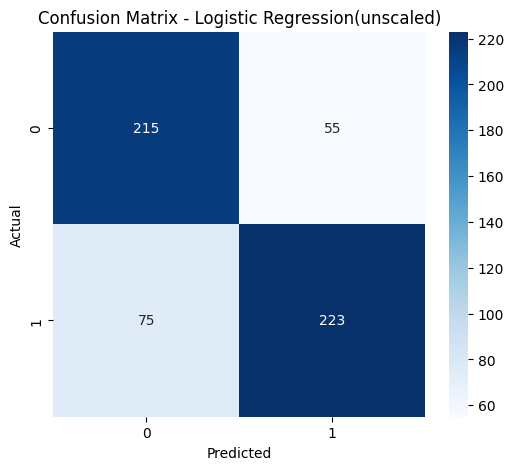

In [ ]:
plot_confusion_matrix(y_test, y_pred_lr2, "Logistic Regression(unscaled)")

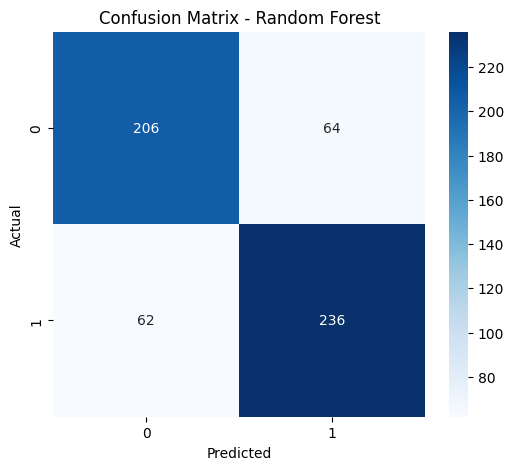

In [ ]:
plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")

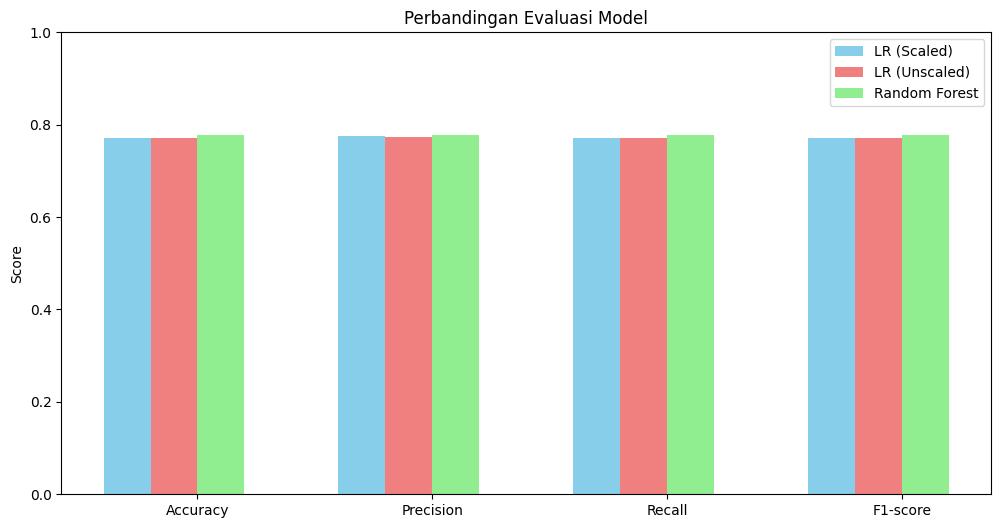

In [ ]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

lr_scores = [
    accuracy_score(y_test, y_pred_lr),
    precision_score(y_test, y_pred_lr, average='weighted', zero_division=0),
    recall_score(y_test, y_pred_lr, average='weighted', zero_division=0),
    f1_score(y_test, y_pred_lr, average='weighted', zero_division=0)
]

lr2_scores = [
    accuracy_score(y_test, y_pred_lr2),
    precision_score(y_test, y_pred_lr2, average='weighted', zero_division=0),
    recall_score(y_test, y_pred_lr2, average='weighted', zero_division=0),
    f1_score(y_test, y_pred_lr2, average='weighted', zero_division=0)
]

rf_scores = [
    accuracy_score(y_test, y_pred_rf),
    precision_score(y_test, y_pred_rf, average='weighted', zero_division=0),
    recall_score(y_test, y_pred_rf, average='weighted', zero_division=0),
    f1_score(y_test, y_pred_rf, average='weighted', zero_division=0)
]



x = np.arange(len(metrics)) * 1.5
width = 0.3

plt.figure(figsize=(12,6))

plt.bar(x - 0.45, lr_scores, width, label='LR (Scaled)', color='skyblue')
plt.bar(x - 0.15, lr2_scores, width, label='LR (Unscaled)', color='lightcoral')
plt.bar(x + 0.15, rf_scores, width, label='Random Forest', color='lightgreen')

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.ylim(0,1)
plt.title('Perbandingan Evaluasi Model')
plt.legend()

#Prediksi

In [ ]:
df_pred = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred_lr': y_pred_lr,
    'y_pred_lr2': y_pred_lr2,
    'y_pred_rf': y_pred_rf
})

df_pred.head(10)


,y_true,y_pred_lr,y_pred_lr2,y_pred_rf
0,1,1,1,1
1,1,1,1,1
2,0,1,1,0
3,1,1,1,1
4,0,0,0,0
5,0,0,0,0
6,0,1,1,0
7,1,1,1,1
8,1,0,0,0
9,0,0,0,0
